 # Sprint 1: Formalización del problema

## Espacio de codificación de soluciones


In [1]:
from itertools import product
from CDP_graph import crear_grafo,visualizar_grafo
import community
import networkx as nx
import numpy as np
import random
from collections import defaultdict

## Codificación de soluciones


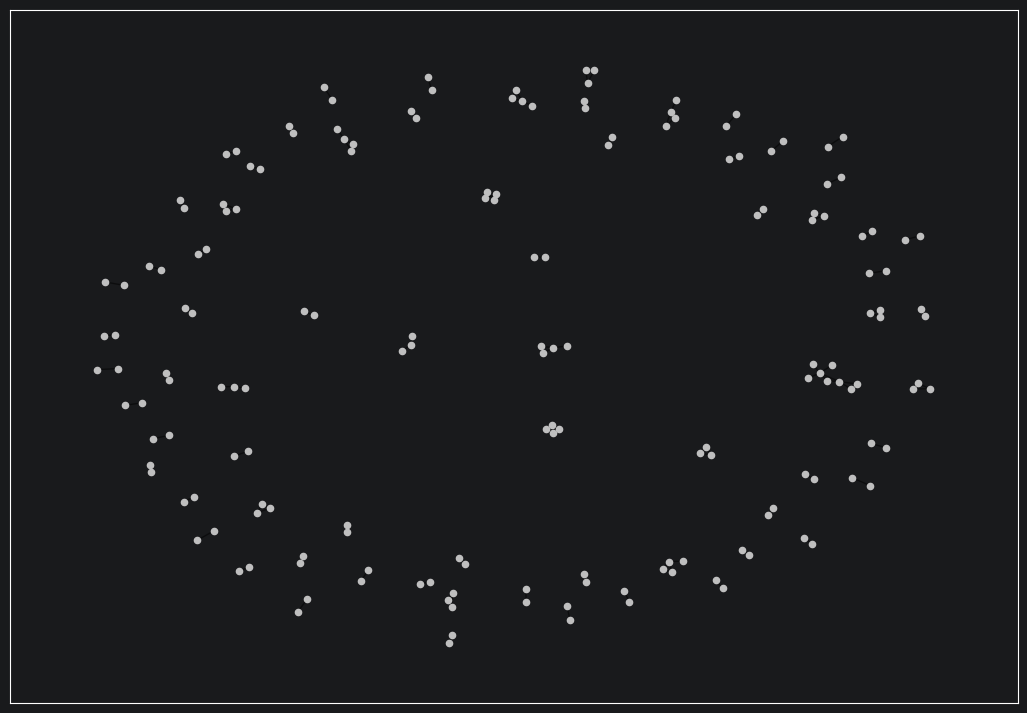

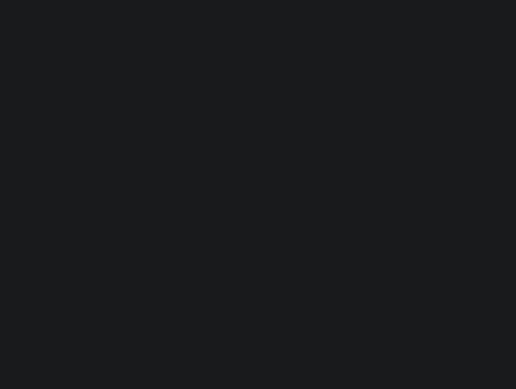

In [26]:
### Propón algunas soluciones al problema como ejemplo
sql = "/home/andoni/Escritorio/HB/Proyecto_HB/DB/database_50.sqlite"
G = crear_grafo(sql)

n = G.number_of_nodes()
rng = random.Random(42)
#solución aleatoria
sol_1 = [rng.randrange(2) for _ in range(n)]
#cada nodo es un cluster
sol_2 = list(range(n))

#TODO: Interesante -> para fase2 solución inicial usando spectral clustering
#sol_3 =...



visualizar_grafo(G)

### Función objetivo


In [31]:
### Función objetivo
def modularidad(G, particion, weight='weight'):
    
    ### TODO 15-20 lineas
    fitness = 0.0
    k = dict(G.degree(weight=weight))   #pesos de las aristas
    m = sum(k.values()) / 2             #peso del grafo

    suma_grados = defaultdict(float)
    peso_interno = defaultdict(float)

    #sumar todos los grados de los autores de una comunidad
    for nodo, grado in k.items():
        comunidad = particion[nodo]
        suma_grados[comunidad] += grado


    #sumar los grados de los nodos que pertenecen a la misma comunidad
    for u, v, datos in G.edges(data=True):
        comunidad_u = particion[u]
        if comunidad_u == particion[v]:
            peso_interno[comunidad_u] += datos.get(weight, 1)

    #ecuación 7 (modularidad)
    for comunidad, grado_total in suma_grados.items():
        a_i = grado_total / (2 * m)
        e_ii = peso_interno[comunidad] / m
        fitness += e_ii - a_i**2
    
    return fitness


## nuestra implementación
partition1 = dict(zip(G.nodes, sol_1))
partition2 = dict(zip(G.nodes, sol_2))

print("Fitness solucion 1: {} ".format(modularidad(G, partition1)))
print("Fitness solucion 2: {} ".format(modularidad(G, partition2)))


# Convertir las particiones al formato de NetworkX
comunidades_1 = defaultdict(set)
comunidades_2 = defaultdict(set)

for nodo, comunidad in partition1.items():
    comunidades_1[comunidad].add(nodo)

for nodo, comunidad in partition2.items():
    comunidades_2[comunidad].add(nodo)
# Comparar resultados con NetworkX
print(f"Fitness solución 1 (NetworkX): {nx.community.modularity(G, list(comunidades_1.values()))}")
print(f"Fitness solución 2 (NetworkX): {nx.community.modularity(G, list(comunidades_2.values()))}")

Fitness solucion 1: -0.04249529696318197 
Fitness solucion 2: -0.007256113947863461 
Fitness solución 1 (NetworkX): -0.04249529696318191
Fitness solución 2 (NetworkX): -0.007256113947863477
